# Energy vs Delay

One figure per QUBO:
- **a.** the energy each solver found, for every number of sensors
- **b.** the best placement, with every junction colored by how long a leak there takes to be detected

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")          # run everything from the repo root
sys.path.append(".")

import matplotlib.pyplot as plt

from benchmark import plot_delays
from src.metrics import leak_delays, detection_rate
from src.qubo import cutoff
from src.simulate_leaks import load_leak_table
from src.utils import load_all_solutions

sol = load_all_solutions()
solvers = ["gurobi", "sa", "qaoa"]      # qaoa is drawn once its solutions are saved
colors = {"gurobi": "black", "sa": "tab:blue", "qaoa": "tab:orange"}
plt.rcParams.update({"font.size": 12})


def qubo_figure(network, qubo, k):
    """a. energy of every solver, b. delay map of the best placement with k sensors."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5.5))
    runs = sol[(sol.network == network) & (sol.formulation == qubo)]

    # a. energy for every number of sensors
    for solver in solvers:
        d = runs[runs.solver == solver].sort_values("k")
        if len(d):
            left.plot(d["k"], d["energy"], marker="o", color=colors[solver], label=solver)
    left.axvline(k, color="lightgray", linestyle="--", zorder=0)
    left.set_xticks(sorted(runs["k"].unique()))
    left.set_xlabel("number of sensors k")
    left.set_ylabel("energy")
    left.set_title("a. energy found by each solver")
    left.legend()

    # b. the lowest energy placement with k sensors, scored on the noisy network
    best = runs[runs.k == k].sort_values("energy").iloc[0]
    delays = leak_delays(load_leak_table(network, noisy=True), best["sensors"])
    plot_delays(network, best["sensors"], delays, ax=right, max_minutes=60)
    right.set_title(f"b. best placement with k = {k}: {detection_rate(delays, cutoff):.0f}% of leaks detected within 30 min")

    fig.suptitle(f"{network}, {qubo} QUBO")
    plt.tight_layout()
    os.makedirs("results/figures", exist_ok=True)
    plt.savefig(f"results/figures/{network}_{qubo}_k{k}.png", dpi=200)

## Net2 with 4 sensors

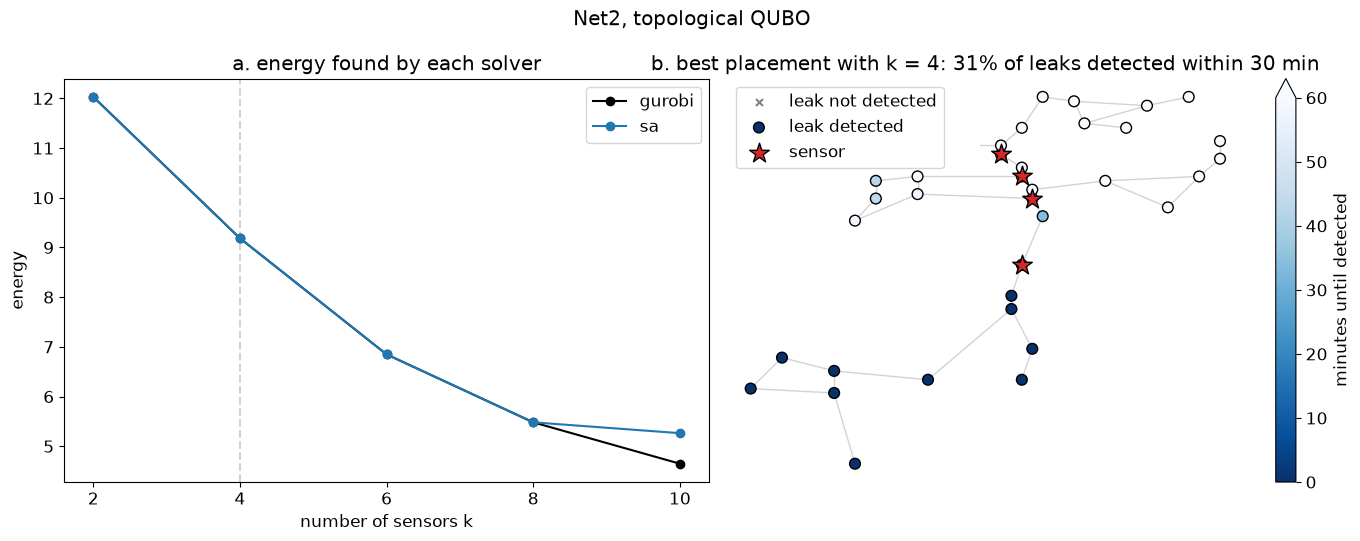

In [2]:
qubo_figure("Net2", "topological", 4)

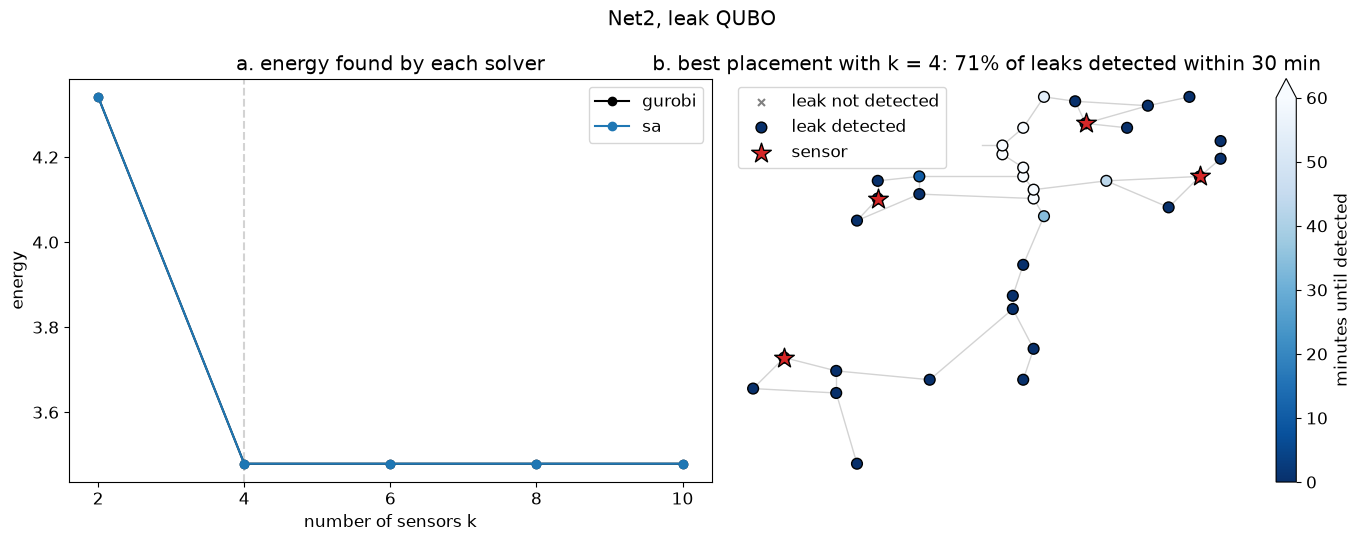

In [3]:
qubo_figure("Net2", "leak", 4)

## Net1 with 2 sensors (the network where QAOA can run)

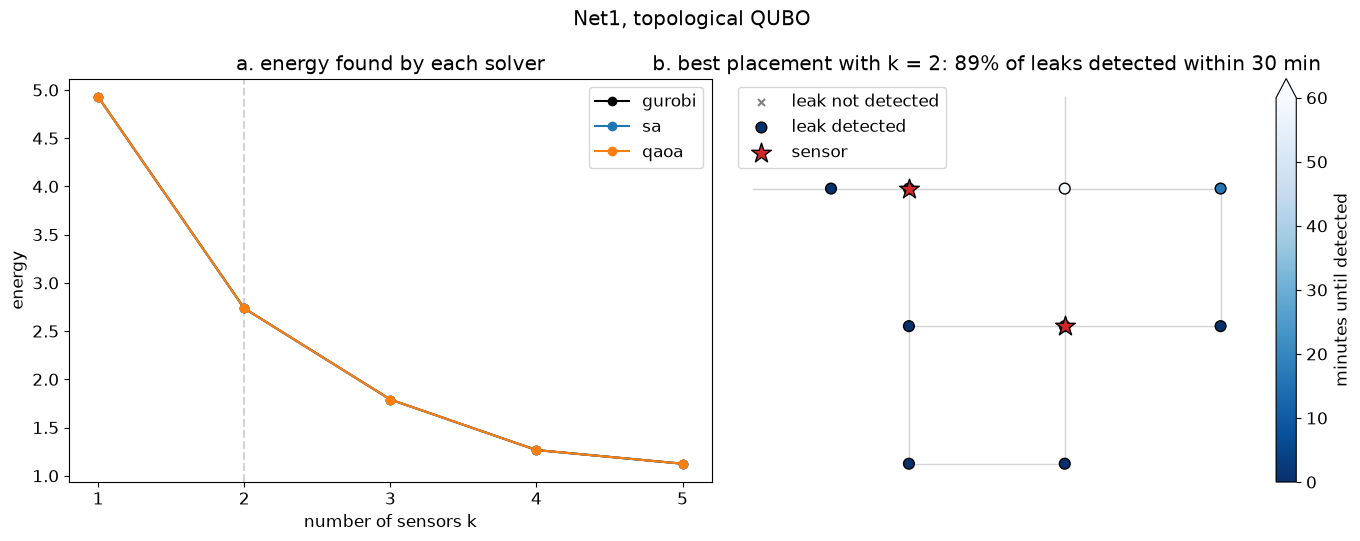

In [4]:
qubo_figure("Net1", "topological", 2)

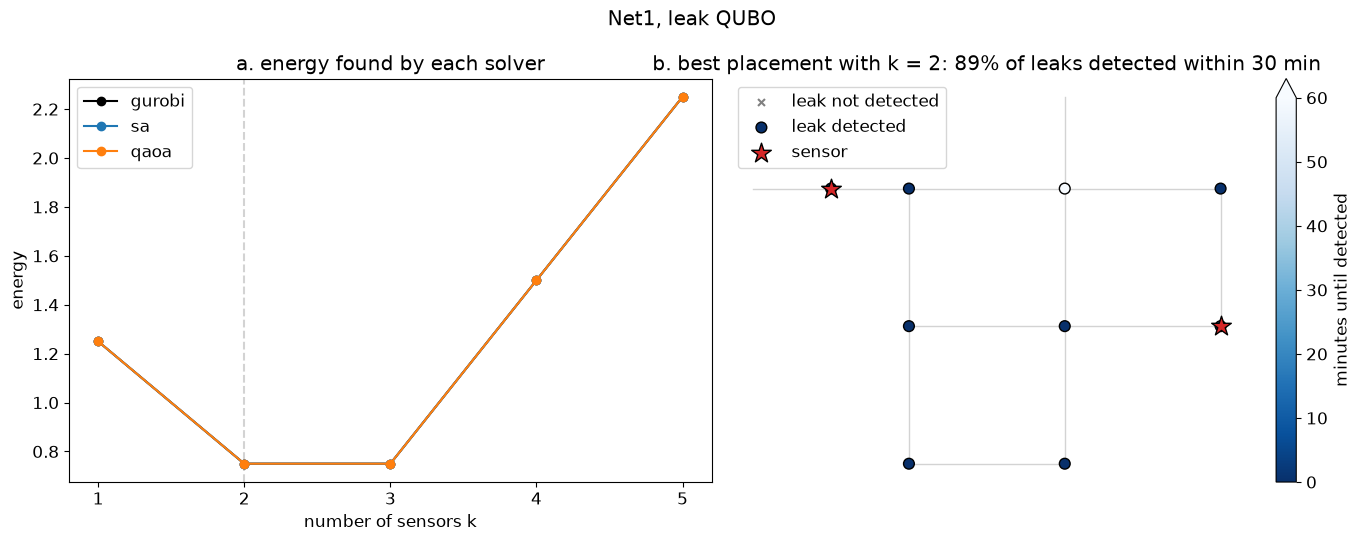

In [5]:
qubo_figure("Net1", "leak", 2)